# **4 - Agrupamento de Trajetórias Temporais (Estágio 2)**

No estágio anterior, criamos um "alfabeto" de 4 Estados de Mortalidade (0 = Crise Aguda, 3 = Baixa Mortalidade). O problema é que analisar observações país-ano de forma independente ignora a evolução demográfica.

Nesta etapa, reintroduzimos o tempo. Nosso objetivo é:
1. Construir uma **Matriz de Sequências Temporais**, onde cada linha é um país e cada coluna é um ano (1950 a 2023). Os valores serão os estados (0 a 3).
2. Visualizar como a mortalidade evoluiu graficamente em cada região do mundo.
3. Preparar esses dados longitudinais para clusterizar os países com base em suas *trajetórias completas*, usando métricas de distância apropriadas para séries temporais (como o *Dynamic Time Warping* - DTW ou Distância de Hamming, já que nossos estados têm durações iguais).

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.colors import ListedColormap
import warnings
warnings.filterwarnings('ignore')

In [26]:
# Configuração visual
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "font.size": 10.5,
    "axes.titlesize": 12.5, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.alpha": 0.25, "legend.frameon": False
})

In [27]:
# 1. Carregando os dados classificados do Estágio 1
df_estados = pd.read_csv('../new_data/wpp2024_estados_mortalidade.csv')

# 2. Criando a Matriz de Sequências Temporais (Pivot Table)
# Linhas = Países, Colunas = Anos, Valores = Estado de Mortalidade
seq_df = df_estados.pivot(index='Pais', columns='Ano', values='Estado_Mortalidade')

# 3. Tratando possíveis NaNs (removendo países sem a série temporal completa)
seq_df = seq_df.dropna()

print(f"Matriz de sequências criada: {seq_df.shape[0]} Países e {seq_df.shape[1]} Anos (1950-2023)")
display(seq_df.head())

Matriz de sequências criada: 161 Países e 74 Anos (1950-2023)


Ano,1950,1951,1952,1953,1954,1955,1956,1957,1958,1959,...,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
Pais,,,,,,,,,,,,,,,,,,,,,
Afghanistan,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,2,2
Albania,0,0,0,0,1,1,1,1,1,1,...,3,3,3,3,3,3,3,3,3,3
Algeria,0,0,0,0,0,0,0,0,0,0,...,2,3,3,3,3,3,2,2,3,3
Angola,0,0,0,0,0,0,0,0,0,0,...,1,1,1,1,1,1,1,1,2,2
Argentina,1,1,1,1,1,1,1,1,1,1,...,3,3,3,3,3,3,3,3,3,3


### **4.1 - Visualizando as Trajetórias (Indexplots)**

Na Análise de Sequências, a ferramenta gráfica padrão é o **Indexplot** (ou gráfico de tapete). Ele empilha as linhas do tempo de todos os países, onde as cores representam o estado em que o país estava em cada ano.

Ordenamos as linhas pelo "histórico de saúde" (a soma dos estados ao longo do tempo) para ver de forma clara a transição demográfica global.

In [28]:
# Definindo um mapa de cores customizado para os 4 estados
# Estado 0 (Pior) = Vermelho Escuro, 1 = Laranja, 2 = Amarelo, 3 (Melhor) = Verde
cmap_estados = ListedColormap(['#D62839', '#F29E4C', '#F1D302', '#2E8B57'])

# Ordenando os países para visualização (do pior histórico geral para o melhor)
seq_ordenada = seq_df.copy()
seq_ordenada['Soma_Estados'] = seq_ordenada.sum(axis=1)
seq_ordenada = seq_ordenada.sort_values(by='Soma_Estados').drop('Soma_Estados', axis=1)

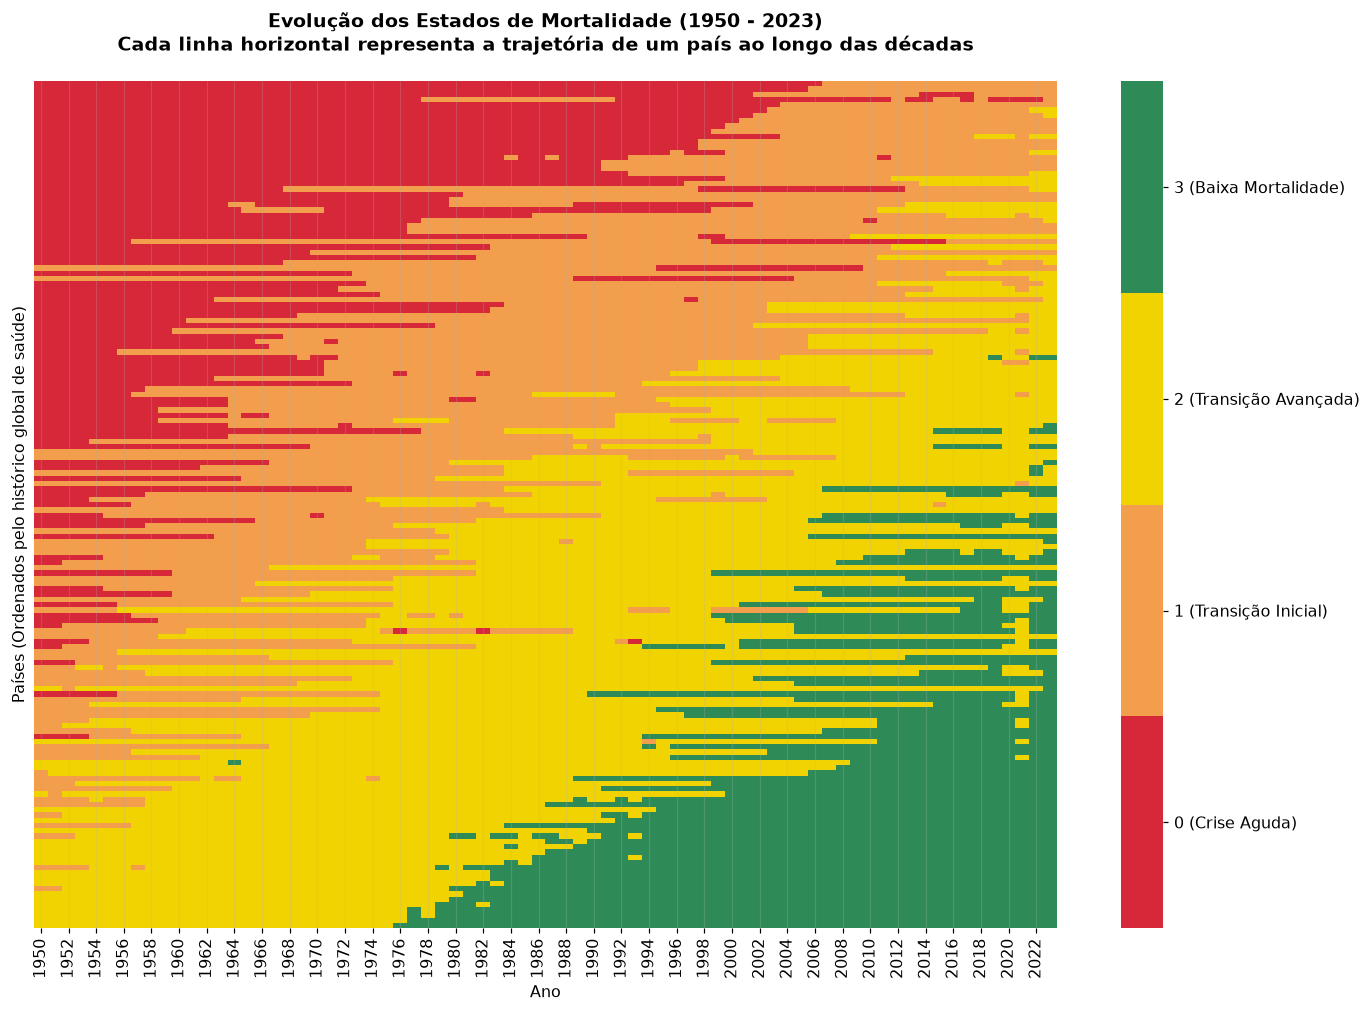

In [30]:
# Plotando a evolução temporal (Indexplot)
plt.figure(figsize=(15, 10))
ax = sns.heatmap(seq_ordenada, cmap=cmap_estados, cbar=True, yticklabels=False)

# Ajustando as legendas da barra de cores
colorbar = ax.collections[0].colorbar
# Como temos 4 estados (0, 1, 2, 3), colocamos os ticks no meio de cada cor
colorbar.set_ticks([0.375, 1.125, 1.875, 2.625]) 
colorbar.set_ticklabels([
    '0 (Crise Aguda)', 
    '1 (Transição Inicial)', 
    '2 (Transição Avançada)', 
    '3 (Baixa Mortalidade)'
])

plt.title('Evolução dos Estados de Mortalidade (1950 - 2023)\nCada linha horizontal representa a trajetória de um país ao longo das décadas', pad=20)
plt.xlabel('Ano')
plt.ylabel('Países (Ordenados pelo histórico global de saúde)')
plt.show()

### **4.2 - Evolução Geográfica dos Estados de Mortalidade e Longevidade (1950 - 2023)**

Para compreender a distribuição espacial da transição demográfica, selecionamos quatro marcos temporais representativos (**1950, 1975, 2000 e 2023**). 

Os mapas ilustram a difusão espacial das conquistas em longevidade:
* **1950:** Predominância global do **Estado 0 (Crise Aguda)** e **Estado 1**, com bolsões restritos de transição avançada na América do Norte, Europa Ocidental e Oceania.
* **1975 a 2000:** Expansão massiva do **Estado 2 (Transição Avançada)** na América Latina e Ásia (impulsionada pela queda da mortalidade infantil) e consolidação do **Estado 3 (Alta Longevidade Idosa)** nos países desenvolvidos.
* **2023:** Convergência da maior parte do globo nos Estados 2 e 3, evidenciando a desigualdade persistente concentrada na África Subsaariana (Estados 0 e 1).

In [31]:
import geopandas as gpd
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
# 1. Carregando o mapa-múndi base
url_mapa = "https://naciscdn.org/naturalearth/110m/cultural/ne_110m_admin_0_countries.zip"
world = gpd.read_file(url_mapa)
# Removendo a Antártida
world = world[world['NAME'] != 'Antarctica']
# =========================================================================
# 🔧 CORREÇÃO DO ISO3 (Resolve o problema do '-99' de França, Noruega e Kosovo)
# =========================================================================
# 1. Usa ISO_A3_EH como base prioritária (onde França é 'FRA' e Noruega é 'NOR')
coluna_base = 'ISO_A3_EH' if 'ISO_A3_EH' in world.columns else 'ADM0_A3'
world['ISO3_FINAL'] = world[coluna_base].replace({'-99': None, -99: None})
# 2. Faz o fallback para ADM0_A3 e ISO_A3 caso algum valor ainda seja nulo
if 'ADM0_A3' in world.columns:
    world['ISO3_FINAL'] = world['ISO3_FINAL'].fillna(world['ADM0_A3'].replace({'-99': None, -99: None}))
if 'ISO_A3' in world.columns:
    world['ISO3_FINAL'] = world['ISO3_FINAL'].fillna(world['ISO_A3'].replace({'-99': None, -99: None}))
# 3. Mapeia o Kosovo (no Natural Earth é 'KOS', mas na ONU/WPP é 'XKX')
world['ISO3_FINAL'] = world['ISO3_FINAL'].replace({'KOS': 'XKX'})
# =========================================================================
# 2. Preparando os dados
df_mapa = df_estados.copy()
# 3. Configurando os anos e as cores oficiais do projeto
anos_escolhidos = [1950, 1964, 1978, 1992, 2006, 2023]
cores_estados = {
    0: '#D62839', # Crise Aguda
    1: '#F29E4C', # Transição Inicial
    2: '#F1D302', # Transição Avançada
    3: '#2E8B57'  # Baixa Mortalidade / Alta Longevidade
}

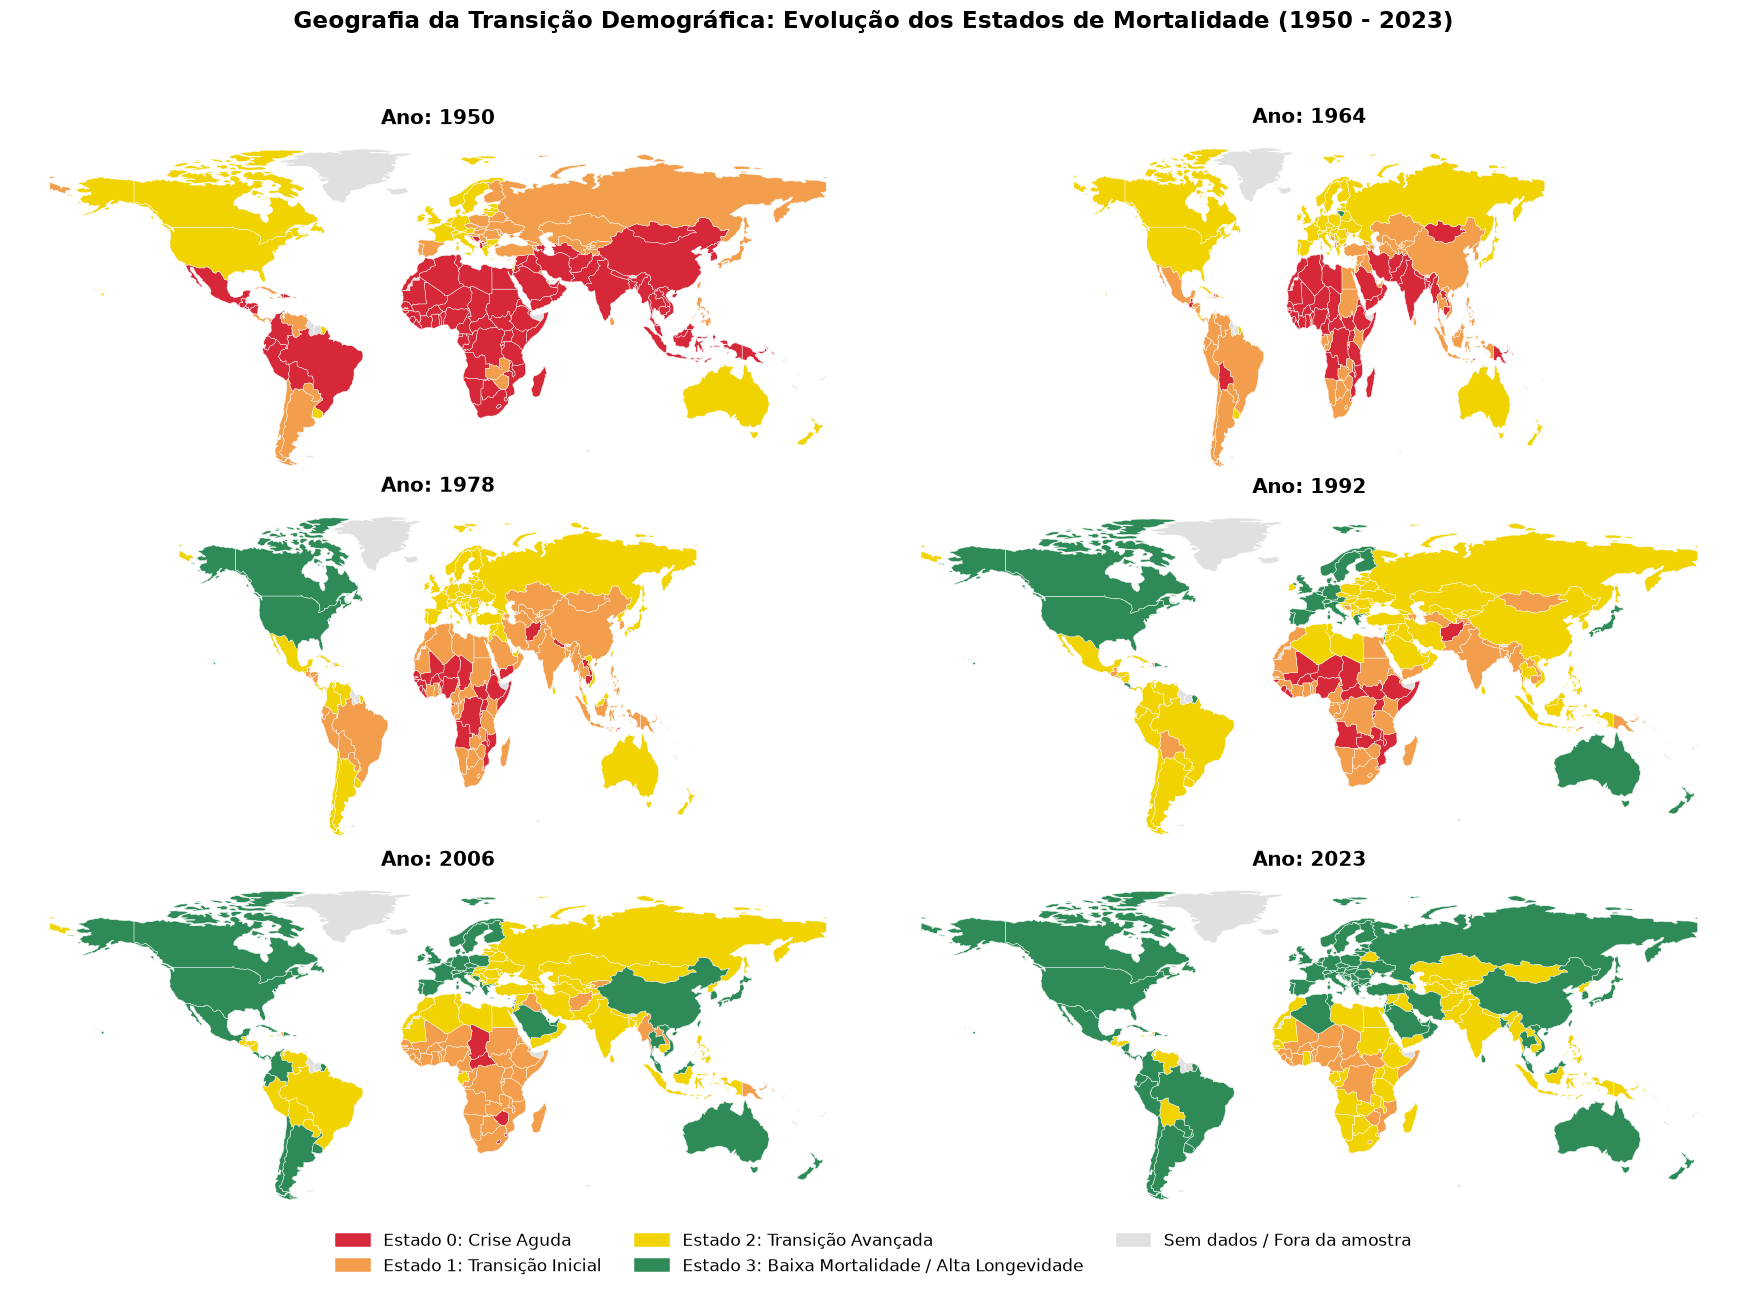

In [32]:
# 1. Adicionamos sharex=True e sharey=True para forçar caixas idênticas
# 2. Ajustamos o figsize para (16, 12), dando mais largura aos mapas que são naturalmente compridos
fig, axes = plt.subplots(3, 2, figsize=(16, 12), sharex=True, sharey=True)
axes = axes.flatten()

for i, ano in enumerate(anos_escolhidos):
    ax = axes[i]
    
    # 3. Trava a proporção geográfica explicitamente
    ax.set_aspect('equal')
    
    dados_ano = df_mapa[df_mapa['Ano'] == ano]
    
    # Faz o merge pela nova coluna tratada 'ISO3_FINAL'
    world_ano = world.merge(dados_ano, how='left', left_on='ISO3_FINAL', right_on='Codigo_ISO3')
    
    # Fundo cinza claro para países sem registros na amostra
    world.plot(ax=ax, color='#E0E0E0', edgecolor='white', linewidth=0.3)
    
    # Plotar cada Estado de Mortalidade com a respectiva cor
    for estado, cor in cores_estados.items():
        subset = world_ano[world_ano['Estado_Mortalidade'] == estado]
        if not subset.empty:
            subset.plot(ax=ax, color=cor, edgecolor='white', linewidth=0.3)
            
    ax.set_title(f'Ano: {ano}', fontsize=13, fontweight='bold')
    ax.axis('off')

# 4. Legenda unificada na parte inferior (mantemos o seu código que estava ótimo)
patches = [
    mpatches.Patch(color='#D62839', label='Estado 0: Crise Aguda'),
    mpatches.Patch(color='#F29E4C', label='Estado 1: Transição Inicial'),
    mpatches.Patch(color='#F1D302', label='Estado 2: Transição Avançada'),
    mpatches.Patch(color='#2E8B57', label='Estado 3: Baixa Mortalidade / Alta Longevidade'),
    mpatches.Patch(color='#E0E0E0', label='Sem dados / Fora da amostra')
]

fig.legend(handles=patches, loc='lower center', ncol=3, frameon=False, fontsize=11, bbox_to_anchor=(0.5, 0.01))
plt.suptitle('Geografia da Transição Demográfica: Evolução dos Estados de Mortalidade (1950 - 2023)', fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()

### **4.3 - Análise de Correspondência (AC): A Dinâmica Espacial-Temporal**

A Análise de Correspondência Simples permite avaliar a associação geométrica entre duas variáveis categóricas. Neste passo, construímos Tabelas de Contingência cruzando **Continentes** (linhas) e **Estados de Mortalidade** (colunas).

Vamos aplicar o algoritmo de AC para dois marcos históricos extremos: **1950 e 2023**. O objetivo é extrair as coordenadas bidimensionais dessa tabela de frequências e plotar um mapa perceptual. 
* A proximidade entre um continente e um Estado de Mortalidade no plano cartesiano indica forte atração estatística.
* A comparação entre os dois anos demonstrará matematicamente o deslocamento dos continentes em direção à consolidação da alta longevidade.

Para garantir o rigor multivariado [(Artes & Barroso, 2023)](https://www.blucher.com.br/metodos-multivariados-de-analise-estatistica-9786555067026), antes de decompor a matriz, avaliamos a associação através do **Teste Qui-Quadrado de Independência**. A rejeição da hipótese nula ($p < 0.05$) justifica a aplicação da AC.

As métricas plotadas no mapa perceptual incluem a **Inércia Total** (que representa o distanciamento da tabela observada em relação à esperada sob independência) e a **Inércia Explicada** por cada dimensão, indicando o percentual de informação contido nos eixos principais.

In [33]:
import pycountry_convert as pc
import prince
from scipy.stats import chi2_contingency

In [34]:
# 1. Função para mapear Continentes
def obter_continente(iso3):
    try:
        iso2 = pc.country_alpha3_to_country_alpha2(iso3)
        cod_continente = pc.country_alpha2_to_continent_code(iso2)
        continentes = {
            'AF': 'África', 'NA': 'América do Norte', 'SA': 'América do Sul', 
            'AS': 'Ásia', 'EU': 'Europa', 'OC': 'Oceania'
        }
        return continentes.get(cod_continente, 'Outros')
    except:
        return 'Outros'

In [35]:
df_mapa['Continente'] = df_mapa['Codigo_ISO3'].apply(obter_continente)
df_ac = df_mapa[df_mapa['Continente'] != 'Outros'].copy()

# 2. Tabelas de Contingência
ct_1950 = pd.crosstab(df_ac[df_ac['Ano'] == 1950]['Continente'], df_ac[df_ac['Ano'] == 1950]['Estado_Mortalidade'])
ct_2023 = pd.crosstab(df_ac[df_ac['Ano'] == 2023]['Continente'], df_ac[df_ac['Ano'] == 2023]['Estado_Mortalidade'])

# 3. Teste Qui-Quadrado de Independência (Validação)
chi2_50, p_50, _, _ = chi2_contingency(ct_1950)
chi2_23, p_23, _, _ = chi2_contingency(ct_2023)
print(f"Teste Qui-Quadrado (1950): Estatística = {chi2_50:.2f}, p-valor = {p_50:.4e}")
print(f"Teste Qui-Quadrado (2023): Estatística = {chi2_23:.2f}, p-valor = {p_23:.4e}")

Teste Qui-Quadrado (1950): Estatística = 93.59, p-valor = 1.0351e-15
Teste Qui-Quadrado (2023): Estatística = 94.35, p-valor = 7.3334e-16


In [36]:
# 4. Ajuste da Análise de Correspondência
ca_1950 = prince.CA(n_components=2, random_state=42).fit(ct_1950)
ca_2023 = prince.CA(n_components=2, random_state=42).fit(ct_2023)

row_1950, col_1950 = ca_1950.row_coordinates(ct_1950), ca_1950.column_coordinates(ct_1950)
row_2023, col_2023 = ca_2023.row_coordinates(ct_2023), ca_2023.column_coordinates(ct_2023)

# Extração robusta do percentual de inércia explicada (compatível com diferentes versões do prince)
perc_1950 = ca_1950.percentage_of_variance_ if hasattr(ca_1950, 'percentage_of_variance_') else ca_1950.explained_inertia_
perc_2023 = ca_2023.percentage_of_variance_ if hasattr(ca_2023, 'percentage_of_variance_') else ca_2023.explained_inertia_

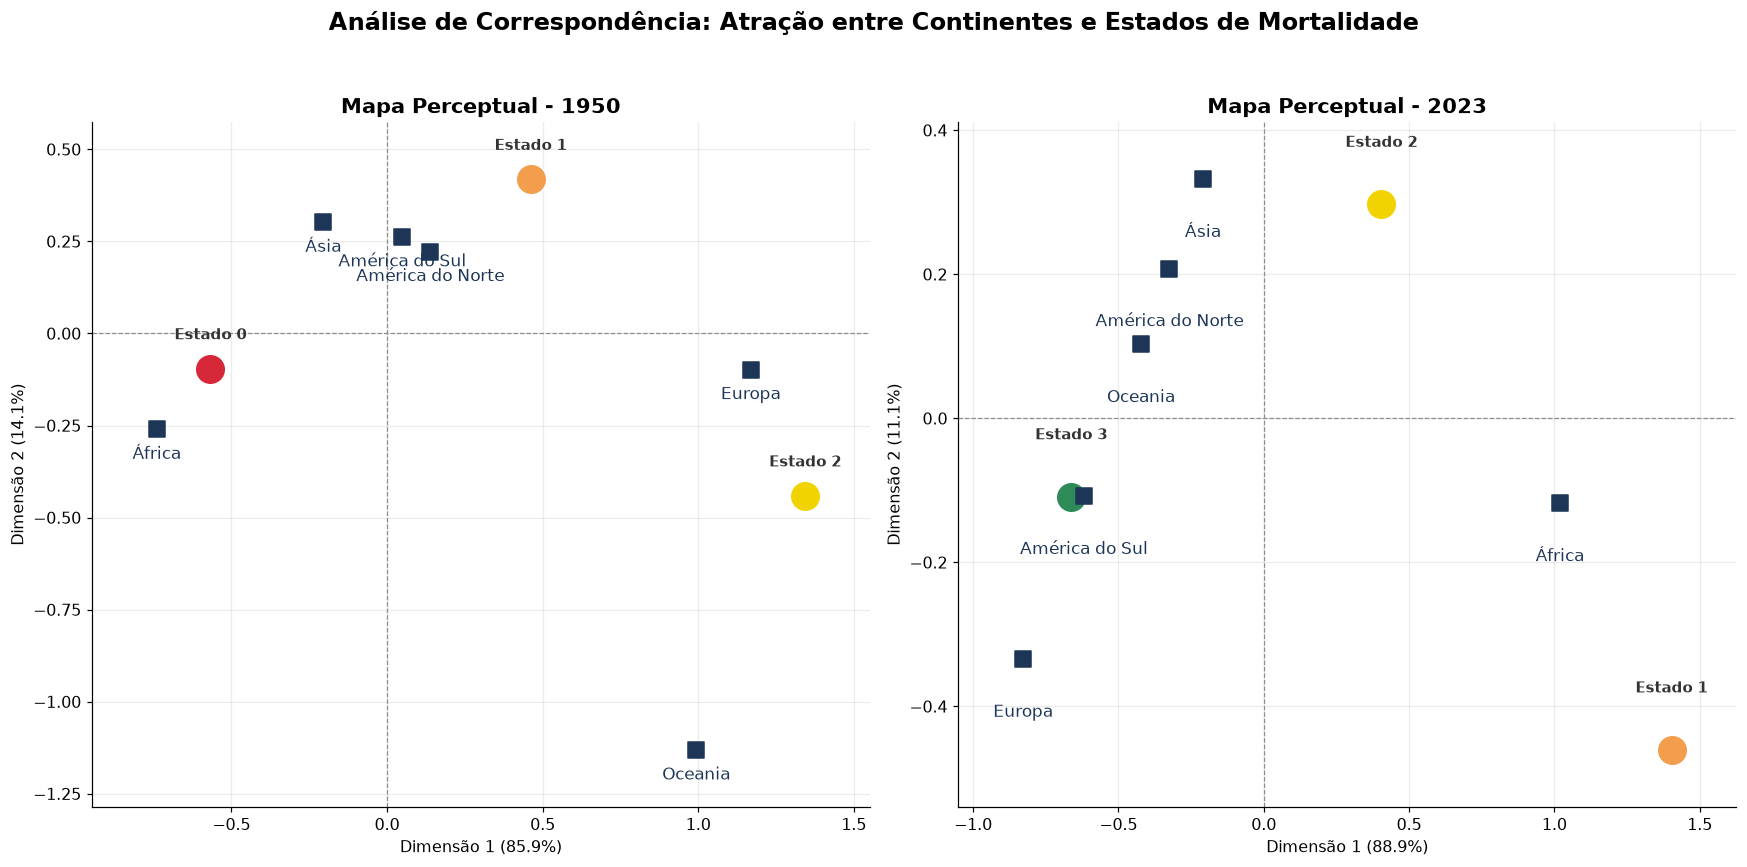

In [37]:
# 5. Plotagem
fig, axes = plt.subplots(1, 2, figsize=(16, 8))
dados_plot = [
    (1950, row_1950, col_1950, perc_1950, axes[0]), 
    (2023, row_2023, col_2023, perc_2023, axes[1])
]

cores_estados = {0: '#D62839', 1: '#F29E4C', 2: '#F1D302', 3: '#2E8B57'}

for ano, row_coords, col_coords, perc, ax in dados_plot:
    for estado in col_coords.index:
        ax.scatter(col_coords.loc[estado].iloc[0], col_coords.loc[estado].iloc[1], 
                   s=400, c=cores_estados.get(estado, '#888888'), edgecolors='white', zorder=3)
        ax.text(col_coords.loc[estado].iloc[0], col_coords.loc[estado].iloc[1] + 0.08, 
                f'Estado {estado}', fontsize=10, fontweight='bold', ha='center', color='#333333')

    for continente in row_coords.index:
        ax.scatter(row_coords.loc[continente].iloc[0], row_coords.loc[continente].iloc[1], 
                   s=100, c='#1D3557', marker='s', zorder=4)
        ax.text(row_coords.loc[continente].iloc[0], row_coords.loc[continente].iloc[1] - 0.08, 
                continente, fontsize=11, ha='center', color='#1D3557')

    # Alargando os eixos automaticamente em 20% para evitar cortes nas bordas
    ax.margins(0.1)
    
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, zorder=1)
    ax.axvline(0, color='gray', linestyle='--', linewidth=0.8, zorder=1)
    
    ax.set_title(f'Mapa Perceptual - {ano}', fontsize=14, fontweight='bold')
    # Adicionando a Inércia Explicada aos eixos!
    ax.set_xlabel(f'Dimensão 1 ({perc[0]:.1f}%)')
    ax.set_ylabel(f'Dimensão 2 ({perc[1]:.1f}%)')

plt.suptitle('Análise de Correspondência: Atração entre Continentes e Estados de Mortalidade', fontsize=16, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

### **4.4 - Agrupamento de Trajetórias Temporais**

Nesta etapa final da modelagem, agrupamos os países com base nas suas trajetórias históricas completas (1950-2023). 

Para isso, utilizamos a **Distância de Hamming**, uma métrica ideal para sequências categóricas alinhadas no tempo, que mede a proporção de discordância entre a linha do tempo de dois países.

Sobre a Matriz de Distâncias gerada, aplicamos a **Clusterização Hierárquica** (método de ligação *Complete* ou *Average*, apropriados para distâncias não-euclidianas). O resultado é visualizado num **Dendrograma**, que nos ajudará a definir o número de macrogrupos (Perfis de Trajetória) ao cortarmos a árvore numa altura ideal.

In [38]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

In [39]:
# 1. Cálculo da Matriz de Distâncias (Distância de Hamming)
# A métrica 'hamming' retorna a proporção de anos em que dois países estiveram em estados diferentes.
# Ex: Se a distância for 0.10, significa que em 10% do tempo (aprox. 7 anos) os países divergiram.
distancias = pdist(seq_ordenada, metric='hamming')

# 2. Aplicando a Clusterização Hierárquica
# Usamos o método 'complete' (distância máxima entre elementos de dois clusters), 
# que tende a gerar clusters mais compactos e esféricos para sequências.
Z = linkage(distancias, method='complete')

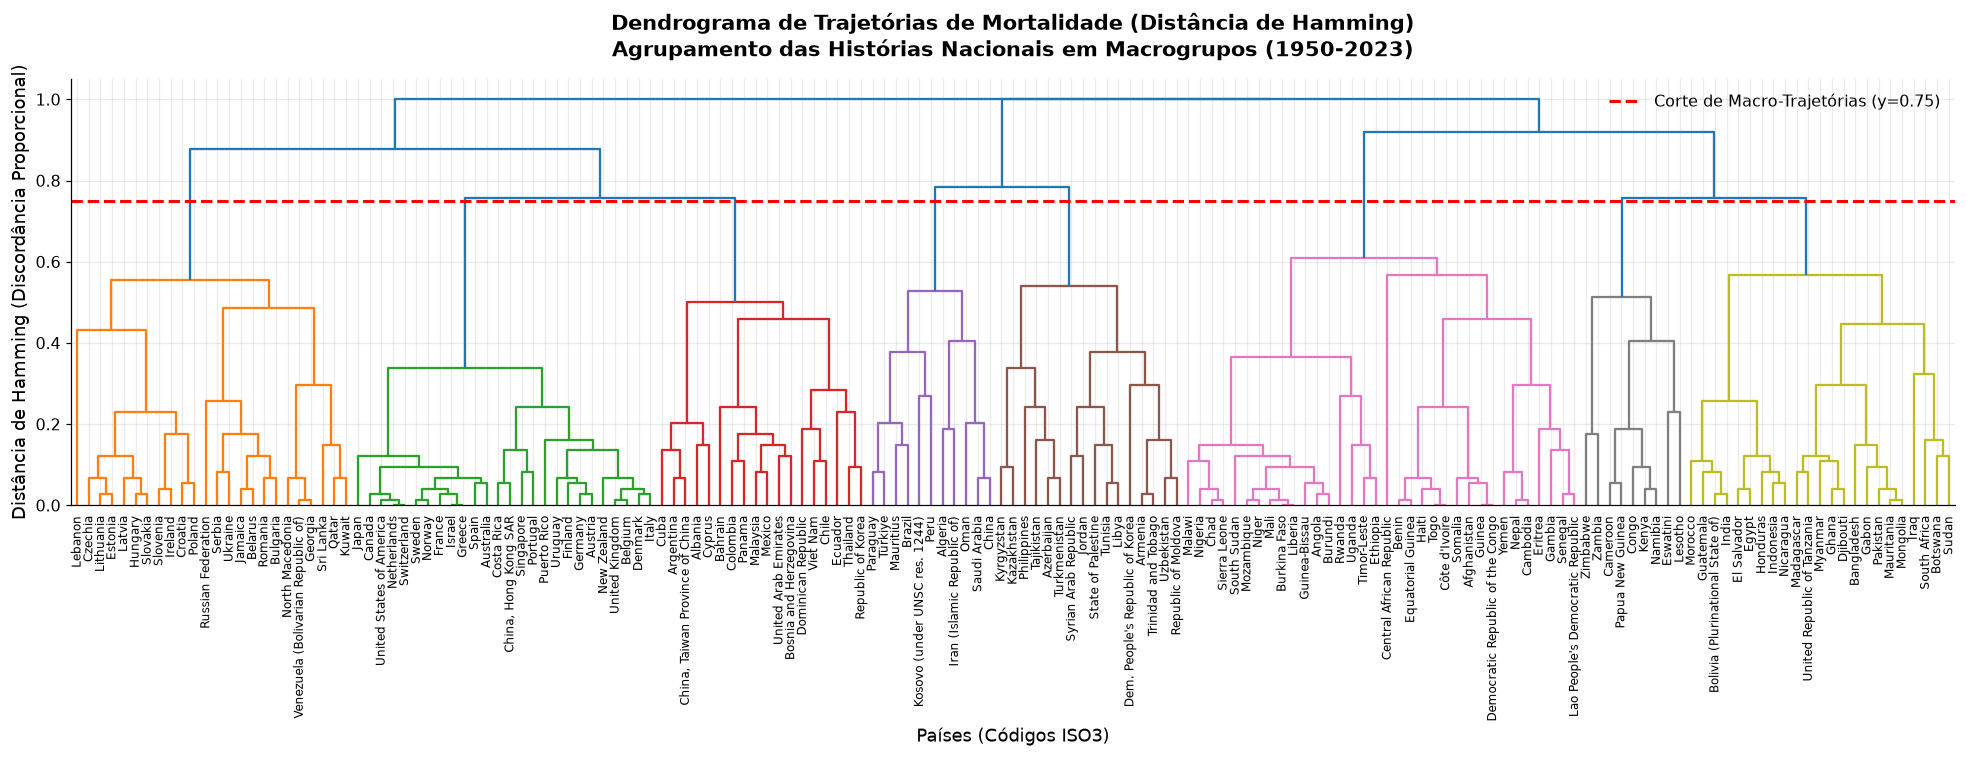

In [40]:
# 2. Definindo o novo corte mais alto para obter menos clusters (macro-trajetórias)
corte_ideal = 0.75

# 3. Plotando o Dendrograma Ajustado
plt.figure(figsize=(18, 7))
dendro = dendrogram(
    Z, 
    labels=seq_ordenada.index, 
    leaf_rotation=90, 
    leaf_font_size=8,
    color_threshold=corte_ideal # As cores agora vão mudar a partir deste corte
)

plt.axhline(y=corte_ideal, color='r', linestyle='--', linewidth=2, label=f'Corte de Macro-Trajetórias (y={corte_ideal})')

plt.title('Dendrograma de Trajetórias de Mortalidade (Distância de Hamming)\nAgrupamento das Histórias Nacionais em Macrogrupos (1950-2023)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Países (Códigos ISO3)', fontsize=12)
plt.ylabel('Distância de Hamming (Discordância Proporcional)', fontsize=12)
plt.legend()
plt.tight_layout()
plt.show()

In [41]:
# 4. EXTRAINDO OS CLUSTERS FINAIS PARA OS PAÍSES
# A função fcluster corta a árvore na distância especificada e devolve o ID do grupo
clusters_finais = fcluster(Z, corte_ideal, criterion='distance')

# Adicionamos essa nova classificação ao nosso DataFrame de sequências
seq_ordenada['Perfil_Trajetoria'] = clusters_finais

# 5. Listando alguns países de cada Perfil de Trajetória para podermos batizá-los
print("\n--- AMOSTRA DE PAÍSES POR PERFIL DE TRAJETÓRIA TEMPORAL ---")
for cluster_id in sorted(seq_ordenada['Perfil_Trajetoria'].unique()):
    paises_no_grupo = seq_ordenada[seq_ordenada['Perfil_Trajetoria'] == cluster_id].index.tolist()
    print(f"\nPerfil {cluster_id} (Total: {len(paises_no_grupo)} países):")
    # Mostra os 10 primeiros países de cada grupo como exemplo
    print(", ".join(paises_no_grupo[:10]))


--- AMOSTRA DE PAÍSES POR PERFIL DE TRAJETÓRIA TEMPORAL ---

Perfil 1 (Total: 24 países):
Venezuela (Bolivarian Republic of), Georgia, North Macedonia, Russian Federation, Lebanon, Jamaica, Belarus, Sri Lanka, Romania, Serbia

Perfil 2 (Total: 26 países):
Singapore, Portugal, Costa Rica, Uruguay, Finland, Germany, China, Hong Kong SAR, Austria, Puerto Rico, United Kingdom

Perfil 3 (Total: 18 países):
Thailand, Malaysia, Bahrain, Mexico, Republic of Korea, United Arab Emirates, Colombia, Bosnia and Herzegovina, Ecuador, Viet Nam

Perfil 4 (Total: 11 países):
Algeria, Iran (Islamic Republic of), Oman, Kosovo (under UNSC res. 1244), Peru, Saudi Arabia, China, Paraguay, Mauritius, Brazil

Perfil 5 (Total: 16 países):
Azerbaijan, Turkmenistan, Tajikistan, Kyrgyzstan, Tunisia, State of Palestine, Kazakhstan, Libya, Philippines, Dem. People's Republic of Korea

Perfil 6 (Total: 34 países):
Chad, Sierra Leone, South Sudan, Central African Republic, Nigeria, Angola, Burundi, Mozambique, Niger

A aplicação da Clusterização Hierárquica sobre a Matriz de Distância de Hamming revelou 8 grandes "Macrogrupos de Trajetória". O algoritmo conseguiu capturar não apenas a velocidade da transição demográfica, mas também os choques históricos sofridos por algumas regiões:

* **Perfil 2: Vanguarda da Longevidade (Pioneiros):** Agrupa nações desenvolvidas (Alemanha, Reino Unido, Finlândia, Cingapura, Portugal). Estes países iniciaram a série histórica já em estados avançados de saúde e consolidaram rapidamente a alta longevidade idosa (Estado 3).
* **Perfil 3: Transição Acelerada (Milagres Econômicos):** Países que deram saltos formidáveis na saúde pública em tempo recorde, como os "Tigres Asiáticos" (Coreia do Sul, Malásia, Vietnã) e o México.
* **Perfil 4: Transição Gradual Consolidada (Grandes Emergentes):** Onde o **Brasil** e a **China** se encontram (junto com Argélia e Peru). Tiveram uma transição muito clássica, cadenciada e paralela, saindo da alta mortalidade nos anos 50 (Estado 1), reduzindo a mortalidade infantil gradualmente até alcançarem recentemente o Estado 3.
* **Perfil 1: Transição com Retrocessos (Choques Estruturais):** Perfil fortemente marcado por países do Leste Europeu (Rússia, Bielorrússia, Romênia, Sérvia) e nações em crises profundas recentes (Venezuela, Líbano). Fizeram a transição, mas a linha do tempo é acidentada devido a picos anômalos de mortalidade adulta (ex: colapso soviético nos anos 90).
* **Perfil 5: Estagnação Intermediária:** Países que melhoraram inicialmente, mas paralisaram devido a ditaduras, isolamento ou guerras civis (Coreia do Norte, Líbia, Turcomenistão, Síria/Palestina).
* **Perfil 8: Transição Tardia em Ascensão:** Sul da Ásia e África emergente (Bangladesh, Paquistão, Gana, Botsuana). Começaram em Crise Aguda (Estado 0), demoraram a arrancar, mas nas últimas duas décadas engrenaram uma transição veloz para os Estados 1 e 2.
* **Perfil 6: Crise Crônica (Retardatários da Transição):** A porção mais vulnerável da África Subsaariana (Chade, Níger, Mali, Sudão do Sul). Linhas do tempo predominantemente paralisadas no Estado 0 (Crise Aguda), com a mortalidade infantil cedendo apenas nos anos mais recentes.
* **Perfil 7: O Choque Epidemiológico do HIV/AIDS:** **A descoberta mais refinada do modelo.** Agrupa os países da África Austral (Eswatini, Lesoto, Zimbábue, Zâmbia, Namíbia). Estas nações estavam em franca melhoria nos anos 70/80 (Estado 1), mas as suas linhas do tempo despencaram de volta para o Estado 0 nos anos 90 e 2000 devido à explosão da epidemia de HIV (mortalidade adulta extrema), e só começaram a se recuperar com os antirretrovirais na última década.